# Route B (fly, available now): optic lobe vs central brain with age (GEO GSE153165)

Choose **Runtime → Run all**. The guide (PDF, Part 1) explains every cell.

In [ ]:
#@title Cell 1 - Setup, settings and connect Google Drive
import glob, gzip, io, os, re, subprocess, tarfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
try:
    from IPython.display import display
except ImportError:
    display = print

DATA_DIR = "/content/drive/MyDrive/Colab Notebooks/route_b_fly_bulk"  #@param {type:"string"}
GTF_PATH = "/content/drive/MyDrive/Colab Notebooks/route_b_fly/Drosophila_melanogaster.gtf.gz"  #@param {type:"string"}
DATA_DIR = os.environ.get("ROUTE_BB_DATA", DATA_DIR)
GTF_PATH = os.environ.get("ROUTE_BB_GTF", GTF_PATH)
if DATA_DIR.startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")
os.makedirs(DATA_DIR, exist_ok=True)


class StopHere(Exception):
    """Stops the notebook with a plain-language message."""


GSE = "GSE153165"
N_RANDOM_SETS = 500  #@param {type:"integer"}
SEED = 1  #@param {type:"integer"}
FDR_MAX, RANDOM_P_MAX, CONTROL_P_MAX = 0.05, 0.05, 0.05
rng = np.random.default_rng(SEED)
print("Data folder:", DATA_DIR)

Mounted at /content/drive
Data folder: /content/drive/MyDrive/Colab Notebooks/route_b_fly_bulk


In [ ]:
#@title Cell 2 - Download the GEO files (a few minutes the first time)
GEO = f"https://ftp.ncbi.nlm.nih.gov/geo/series/{GSE[:-3]}nnn/{GSE}"


def fetch(url, path):
    if os.path.exists(path) and os.path.getsize(path) > 0:
        print(f"   {os.path.basename(path)}: already downloaded")
        return True
    r = subprocess.run(["curl", "-fsSL", "-m", "3600", "-o", path + ".part", url], capture_output=True, text=True)
    if r.returncode != 0 or not os.path.exists(path + ".part") or os.path.getsize(path + ".part") == 0:
        print(f"   {os.path.basename(path)}: FAILED ({r.stderr.strip()[:120]})")
        if os.path.exists(path + ".part"):
            os.remove(path + ".part")
        return False
    os.replace(path + ".part", path)
    print(f"   {os.path.basename(path)}: {os.path.getsize(path) / 1e6:.1f} MB")
    return True


fetch(f"{GEO}/matrix/{GSE}_series_matrix.txt.gz", os.path.join(DATA_DIR, f"{GSE}_series_matrix.txt.gz"))
page = subprocess.run(["curl", "-fsSL", "-m", "120", f"{GEO}/suppl/"], capture_output=True, text=True).stdout
names = sorted(set(re.findall(r'href="(GSE[^"/]+)"', page)))
print("\nSupplementary files on GEO:", names or "(could not list; files already in your folder will be used)")
tables = [n for n in names if not n.endswith(".tar") and re.search(r"count|fpkm|tpm|rpkm|express|matrix|txt|csv|tsv|xls", n, re.I)]
for n in tables:
    fetch(f"{GEO}/suppl/{n}", os.path.join(DATA_DIR, n))
if not tables and f"{GSE}_RAW.tar" in names:
    print("No combined table; downloading the per-sample archive instead")
    fetch(f"{GEO}/suppl/{GSE}_RAW.tar", os.path.join(DATA_DIR, f"{GSE}_RAW.tar"))
for tar in glob.glob(os.path.join(DATA_DIR, "*.tar")):
    out = os.path.join(DATA_DIR, "raw")
    if not os.path.isdir(out):
        with tarfile.open(tar) as t:
            t.extractall(out)
    print(f"   unpacked {os.path.basename(tar)}: {len(os.listdir(out))} files")
if not os.path.exists(os.path.join(DATA_DIR, f"{GSE}_series_matrix.txt.gz")):
    raise StopHere("The sample information file could not be downloaded. Run this cell again; if it still fails, send me the output.")
if not os.path.exists(GTF_PATH):
    raise StopHere(f"Gene annotation not found at {GTF_PATH}. Fix GTF_PATH in Cell 1.")
print("Done.")

   GSE153165_series_matrix.txt.gz: already downloaded

Supplementary files on GEO: ['GSE153165_polyploidy_depth_normalized_counts.xlsx']
   GSE153165_polyploidy_depth_normalized_counts.xlsx: already downloaded
Done.


In [ ]:
#@title Cell 3 - Build the expression table and read sample information
# Gene IDs to symbols, from the fly annotation
id2sym = {}
with gzip.open(GTF_PATH, "rt") as h:
    for line in h:
        if "\tgene\t" in line:
            gid = re.search(r'gene_id "([^"]+)"', line); sym = re.search(r'gene_name "([^"]+)"', line)
            if gid:
                id2sym[gid.group(1)] = sym.group(1) if sym else gid.group(1)

# Sample information from the series matrix
meta = {}
with gzip.open(os.path.join(DATA_DIR, f"{GSE}_series_matrix.txt.gz"), "rt", errors="replace") as h:
    for line in h:
        if line.startswith("!Sample_"):
            key, *vals = line.rstrip("\n").split("\t")
            meta.setdefault(key, []).append([v.strip('"') for v in vals])
samples = pd.DataFrame({"gsm": meta["!Sample_geo_accession"][0], "title": meta["!Sample_title"][0]})
samples["text"] = [" | ".join(str(v[i]) for k, vs in meta.items() for v in vs if i < len(v)) for i in range(len(samples))]


def read_table(path):
    opener = gzip.open if path.endswith(".gz") else open
    if re.search(r"\.xlsx?$", path):
        return pd.read_excel(path)
    with opener(path, "rt", errors="replace") as h:
        head = h.read(5000)
    sep = "," if head.count(",") > head.count("\t") else "\t"
    return pd.read_csv(path, sep=sep, comment=None, low_memory=False)


def as_matrix(table):
    """Gene x sample numbers from a table whose first text column holds gene IDs or symbols."""
    text_cols = [c for c in table.columns if not pd.api.types.is_numeric_dtype(table[c])]
    num_cols = [c for c in table.columns if pd.api.types.is_numeric_dtype(table[c])]
    if not text_cols or not num_cols:
        return None
    key = max(text_cols, key=lambda c: table[c].astype(str).str.match(r"^FBgn\d+").mean())
    genes = table[key].astype(str).map(lambda g: id2sym.get(g.split(".")[0], g))
    m = table[num_cols].set_index(genes).groupby(level=0).sum()
    return m.loc[:, [c for c in m.columns if not re.search(r"length|^start|^end|chr", str(c), re.I)]]


candidates = [p for p in glob.glob(os.path.join(DATA_DIR, f"{GSE}*")) if not re.search(r"series_matrix|\.tar$", p)]
expr = None
for p in candidates:
    try:
        m = as_matrix(read_table(p))
    except Exception as error:
        print(f"   could not read {os.path.basename(p)}: {type(error).__name__}")
        continue
    if m is not None and m.shape[1] >= 6 and m.shape[0] > 5000:
        expr = m
        print(f"   using {os.path.basename(p)}: {m.shape[0]:,} genes x {m.shape[1]} samples")
        break
if expr is None and os.path.isdir(os.path.join(DATA_DIR, "raw")):
    cols = {}
    for p in sorted(glob.glob(os.path.join(DATA_DIR, "raw", "*"))):
        try:
            m = as_matrix(read_table(p))
        except Exception:
            continue
        if m is not None and m.shape[0] > 5000:
            cols[os.path.basename(p).split("_")[0]] = m.iloc[:, -1]
    if len(cols) >= 6:
        expr = pd.DataFrame(cols).fillna(0)
        print(f"   built from {len(cols)} per-sample files: {expr.shape[0]:,} genes")
if expr is None:
    raise StopHere("No expression table found among the GEO files. Send me the file list printed in Cell 2.")

# Match each expression column to a GEO sample: first by any shared ID, otherwise by order
def match(col):
    c = str(col)
    code = re.sub(r"^\D+", "", c)
    for i, r in samples.iterrows():
        if c in (r.gsm, r.title) or r.gsm in c or (len(r.title) > 3 and r.title in c):
            return i
        if len(code) >= 4 and re.search(rf"\b{code}\b", r.text):
            return i
    return None


hits = [match(c) for c in expr.columns]
if sum(h is not None for h in hits) == expr.shape[1]:
    info = samples.loc[hits].reset_index(drop=True)
    info["column"] = list(expr.columns)
    print("Matched every expression column to a GEO sample by name.")
    by_order = False
elif expr.shape[1] == len(samples):
    info = samples.copy().reset_index(drop=True)
    info["column"] = list(expr.columns)
    print(f"The expression columns ({expr.columns[0]}, ...) do not name the GEO samples.")
    print(f"There are {expr.shape[1]} columns and {len(samples)} GEO samples, so they are matched IN ORDER.")
    print("This is checked below: replicates of the same group should resemble each other most.")
    by_order = True
else:
    raise StopHere(f"The table has {expr.shape[1]} sample columns but GEO lists {len(samples)} samples, and "
                   "the column names do not match. Send me this message.")

# Labels from titles such as 0dFemaleOL1 (age, sex, region, replicate) or from the descriptions
t = info.title.astype(str)
low = (info.title + " | " + info.text).str.lower()
info["region"] = t.str.extract(r"(OL|CB|VNC)\d*$", expand=False)
alt = np.select([low.str.contains("optic"), low.str.contains("central brain"), low.str.contains("ventral")],
                ["OL", "CB", "VNC"], "unknown")
info["region"] = info["region"].fillna(pd.Series(alt))
info["age_days"] = t.str.extract(r"^(\d+)\s*d", expand=False).astype(float)
info["age_days"] = info["age_days"].fillna(low.str.extract(r"(\d+)\s*(?:d\b|day)", expand=False).astype(float))
tl = t.str.lower()       # the title is the most reliable source (e.g. 21dMaleCB2); descriptions can mention both sexes
info["sex"] = np.select([tl.str.contains("female"), tl.str.contains("male"),
                         low.str.contains("female") & ~low.str.contains(r"\bmale"), low.str.contains(r"\bmale")],
                        ["F", "M", "F", "M"], "unknown")
info["group"] = info.title.str.replace(r"\d+$", "", regex=True)

sheet = os.path.join(DATA_DIR, "sample_labels.csv")
auto_ok = not (info.region.isin(["unknown"]) | info.region.isna() | info.age_days.isna() | (info.sex == "unknown")).any()
if os.path.exists(sheet) and not auto_ok:
    info = pd.read_csv(sheet)
    print("Using your edited sample_labels.csv")
else:
    info[["column", "gsm", "title", "group", "region", "age_days", "sex"]].to_csv(sheet, index=False)
display(info[["column", "gsm", "title", "region", "age_days", "sex"]])
bad = info.region.isin(["unknown"]) | info.region.isna() | info.age_days.isna()
if bad.any():
    raise StopHere(f"{int(bad.sum())} samples could not be labelled. Open sample_labels.csv in your Drive folder, fill in "
                   "region (OL, CB or VNC), age_days and sex, save, and run this cell again.")
print(info.groupby(["region", "age_days"]).size().unstack(fill_value=0))
print(info.groupby(["region", "sex"]).size().unstack(fill_value=0))

# Check: is each sample most similar to a replicate of its own group?
L = np.log2(expr[info.column].astype(float) + 1)
L = L[(L > 3).mean(axis=1) >= 0.8]
L = L.loc[L.var(axis=1).sort_values().index[-2000:]]      # the 2,000 most variable expressed genes
C = np.corrcoef((L.sub(L.mean(axis=1), axis=0)).T.to_numpy())
np.fill_diagonal(C, -1)
nearest = C.argmax(axis=1)
same_group = (info.group.to_numpy()[nearest] == info.group.to_numpy()).mean()
same_region = (info.region.to_numpy()[nearest] == info.region.to_numpy()).mean()
print(f"\nCheck: nearest neighbour is a replicate of the same group for {100 * same_group:.0f}% of samples, "
      f"and from the same region for {100 * same_region:.0f}%")
if same_region < 0.8:
    msg = "Samples do not group by region as expected."
    if by_order:
        msg += " The column order probably does not follow GEO's sample order."
    raise StopHere(msg + " Do not go on; send me this output.")
print("Labels look right: samples group by region.")

   using GSE153165_polyploidy_depth_normalized_counts.xlsx: 16,343 genes x 72 samples
The expression columns (Sample_72006, ...) do not name the GEO samples.
There are 72 columns and 72 GEO samples, so they are matched IN ORDER.
This is checked below: replicates of the same group should resemble each other most.


,column,gsm,title,region,age_days,sex
0,Sample_72006,GSM4635092,0dFemaleOL1,OL,0.0,F
1,Sample_72007,GSM4635093,0dFemaleOL2,OL,0.0,F
2,Sample_72008,GSM4635094,0dFemaleOL3,OL,0.0,F
3,Sample_72009,GSM4635095,0dFemaleCB1,CB,0.0,F
4,Sample_72010,GSM4635096,0dFemaleCB2,CB,0.0,F
...,...,...,...,...,...,...
67,Sample_72073,GSM4635159,21dMaleCB2,CB,21.0,M
68,Sample_72074,GSM4635160,21dMaleCB3,CB,21.0,M
69,Sample_72075,GSM4635161,21dMaleVNC1,VNC,21.0,M
70,Sample_72076,GSM4635162,21dMaleVNC2,VNC,21.0,M


age_days  0.0   2.0   7.0   21.0
region                          
CB           6     6     6     6
OL           6     6     6     6
VNC          6     6     6     6
sex      F   M
region        
CB      12  12
OL      12  12
VNC     12  12

Check: nearest neighbour is a replicate of the same group for 82% of samples, and from the same region for 100%
Labels look right: samples group by region.


In [ ]:
#@title Cell 4 - Normalise and choose expressed genes
X = expr[info.column].astype(float)
integer = np.allclose(X.to_numpy(), np.round(X.to_numpy()))
if integer:
    X = np.log2(X / X.sum() * 1e6 + 1)
    print("Counts found: converted to log2 counts per million")
else:
    X = np.log2(X + 1) if X.max().max() > 50 else X
    print("Normalised values found (FPKM/TPM or similar): log2-transformed")
X.columns = range(X.shape[1])
expressed = X[(X > 1).mean(axis=1) >= 0.5]
print(f"Expressed genes: {len(expressed):,} of {len(X):,}")

Normalised values found (FPKM/TPM or similar): log2-transformed
Expressed genes: 12,048 of 16,343


In [ ]:
#@title Cell 5 - Gene programmes (fly gene symbols)
PROGRAMMES = {
    "REDOX: cnc (NRF2) pathway": "cnc Keap1 Gclc Gclm GstD1 GstD2 GstE1 GstS1 Zw Pgd Men",
    "REDOX: thioredoxin/peroxiredoxin": "Trxr-1 Trxr-2 Trx-2 Jafrac1 Jafrac2 Prx3 Prx5 PHGPx",
    "REDOX: antioxidant enzymes": "Sod1 Sod2 Cat Eip71CD SelR Ogg1",
    "REDOX: iron": "Fer1HCH Fer2LCH Irp1A Tsf1 Mvl",
    "REDOX: mitochondrial respiration": "ND-75 ND-49 ND-30 ND-42 SdhA SdhB UQCR-C1 UQCR-C2 Cyt-c-p COX4 COX5A ATPsynbeta blw",
    "EXPLORE: licensing and cell cycle re-entry": "Gem dup Cdc6 Orc1 Mcm2 Mcm3 dpa Mcm5 Mcm6 Mcm7 CycE E2f1 Myc CycD",
    "EXPLORE: p53 head DNA damage response": "Ku80 Irbp Cht8 CG3344 CG4734 Fanci lok rad50 Xrp1 p53",
    "CONTROL: unfolded protein response": "Hsc70-3 Xbp1 crc PEK Ire1 Atf6 Pdi ERp60 Calr",
    "CONTROL: heat shock": "Hsp70Aa Hsp83 Hsp68 Hsp27 Hsp26 Hsc70-4 DnaJ-1 Hsf",
    "CONTROL: DNA damage": "p53 mei-41 tefu lok spn-A mus304 Xrp1 rpr hid",
    "CONTROL: immediate-early genes": "Hr38 sr kay Jra puc CrebA",
}
PROGRAMMES = {n: [g for g in v.split() if g in expressed.index] for n, v in PROGRAMMES.items()}
for n, v in PROGRAMMES.items():
    print(f"{n}: {len(v)} expressed genes")
PROGRAMMES = {n: v for n, v in PROGRAMMES.items() if len(v) >= 4}

REDOX: cnc (NRF2) pathway: 11 expressed genes
REDOX: thioredoxin/peroxiredoxin: 7 expressed genes
REDOX: antioxidant enzymes: 6 expressed genes
REDOX: iron: 4 expressed genes
REDOX: mitochondrial respiration: 13 expressed genes
EXPLORE: licensing and cell cycle re-entry: 12 expressed genes
EXPLORE: p53 head DNA damage response: 9 expressed genes
CONTROL: unfolded protein response: 9 expressed genes
CONTROL: heat shock: 8 expressed genes
CONTROL: DNA damage: 9 expressed genes
CONTROL: immediate-early genes: 6 expressed genes


In [ ]:
#@title Cell 6 - Screens: does the optic lobe change differently with age from the central brain?
use = info.region.isin(["OL", "CB"]).to_numpy()
d = info[use].reset_index(drop=True)
age = np.log2(d.age_days.to_numpy() + 1)   # +1 because the first time point is day 0
ol = (d.region == "OL").to_numpy(float)
cols = [np.ones(len(d)), ol, age - age.mean(), (age - age.mean()) * ol]
if d.sex.nunique() > 1:
    cols.append((d.sex == "M").to_numpy(float))
D = np.column_stack(cols)
dof = len(d) - np.linalg.matrix_rank(D)
pinv = np.linalg.pinv(D)
c_var = np.linalg.pinv(D.T @ D)[3, 3]
from scipy import stats


def interaction_t(Y):
    """t statistic for (age slope in optic lobe) minus (age slope in central brain), per column of Y."""
    Y = np.asarray(Y, float)
    Y = Y[:, None] if Y.ndim == 1 else Y
    B = pinv @ Y
    resid = Y - D @ B
    s2 = (resid**2).sum(0) / dof
    return B[3] / np.sqrt(s2 * c_var), B[3]


Z = expressed.loc[:, np.flatnonzero(use)].T
Z = (Z - Z.mean()) / Z.std().replace(0, np.nan)
scores = pd.DataFrame({n: Z[v].mean(axis=1).to_numpy() for n, v in PROGRAMMES.items()})
t, b = interaction_t(scores.to_numpy())
result = pd.DataFrame({"programme": scores.columns, "genes": [len(PROGRAMMES[n]) for n in scores.columns],
                       "interaction": b, "t": t, "p": 2 * stats.t.sf(np.abs(t), dof)})
for fam in ("REDOX", "EXPLORE"):
    m = result.programme.str.startswith(fam)
    p = result.loc[m, "p"].to_numpy(); o = np.argsort(p)
    q = np.minimum(np.minimum.accumulate((p[o] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1], 1)
    qq = np.empty_like(q); qq[o] = q; result.loc[m, "q_fdr"] = qq

level = expressed.mean(axis=1)
bins = pd.qcut(level.rank(method="first"), 20, labels=False)
avoid = {g for v in PROGRAMMES.values() for g in v}
by_bin = {b_: [g for g in level.index[bins == b_] if g not in avoid] for b_ in range(20)}
for n in [n for n in scores.columns if not n.startswith("CONTROL")]:
    draws = np.column_stack([Z[[rng.choice(by_bin[bins[g]]) for g in PROGRAMMES[n]]].mean(axis=1) for _ in range(N_RANDOM_SETS)])
    null, _ = interaction_t(draws)
    i = result.programme == n; obs = result.loc[i, "t"].iloc[0]
    result.loc[i, "random_low"], result.loc[i, "random_high"] = np.quantile(null, [0.025, 0.975])
    result.loc[i, "p_vs_random"] = (1 + np.sum(np.abs(null) >= abs(obs))) / (len(null) + 1)
    worst, which = 0.0, ""
    for c in [c for c in scores.columns if c.startswith("CONTROL")]:
        tc, _ = interaction_t(scores[n].to_numpy() - scores[c].to_numpy())
        pc = 2 * stats.t.sf(abs(tc[0]), dof) if np.sign(tc[0]) == np.sign(obs) else 1.0
        if pc >= worst:
            worst, which = pc, c.replace("CONTROL: ", "")
    result.loc[i, "p_vs_controls"], result.loc[i, "closest_control"] = worst, which
ok = (result.q_fdr < FDR_MAX) & (result.p_vs_random < RANDOM_P_MAX) & (result.p_vs_controls < CONTROL_P_MAX)
result["verdict"] = np.where(result.programme.str.startswith("CONTROL"), "(control)",
                    np.where(ok, np.where(result.t > 0, "passes: rises more with age in optic lobe",
                                          "passes: falls more with age in optic lobe"),
                    np.where(result.q_fdr < FDR_MAX, "not specific", "no difference")))
print(f"{len(d)} samples (optic lobe and central brain), {dof} degrees of freedom")
display(result[["programme", "interaction", "t", "q_fdr", "p_vs_random", "p_vs_controls", "verdict"]].round(3))
print("\nFull table (random-set range and closest control):")
display(result.round(3))

48 samples (optic lobe and central brain), 43 degrees of freedom


,programme,interaction,t,q_fdr,p_vs_random,p_vs_controls,verdict
0,REDOX: cnc (NRF2) pathway,-0.108,-2.439,0.047,0.236,0.185,not specific
1,REDOX: thioredoxin/peroxiredoxin,0.038,0.782,0.438,0.705,1.000,no difference
2,REDOX: antioxidant enzymes,-0.077,-1.531,0.166,0.477,0.293,no difference
3,REDOX: iron,-0.183,-2.667,0.047,0.293,0.097,not specific
4,REDOX: mitochondrial respiration,-0.128,-2.013,0.084,0.499,0.065,no difference
5,EXPLORE: licensing and cell cycle re-entry,0.081,2.022,0.049,0.257,1.000,not specific
6,EXPLORE: p53 head DNA damage response,0.223,4.805,0.000,0.002,0.811,not specific
7,CONTROL: unfolded protein response,-0.027,-0.646,NaN,NaN,NaN,(control)
8,CONTROL: heat shock,0.201,2.044,NaN,NaN,NaN,(control)
9,CONTROL: DNA damage,0.155,3.249,NaN,NaN,NaN,(control)



Full table (random-set range and closest control):


,programme,genes,interaction,t,p,q_fdr,random_low,random_high,p_vs_random,p_vs_controls,closest_control,verdict
0,REDOX: cnc (NRF2) pathway,11,-0.108,-2.439,0.019,0.047,-3.510,4.461,0.236,0.185,unfolded protein response,not specific
1,REDOX: thioredoxin/peroxiredoxin,7,0.038,0.782,0.438,0.438,-3.693,3.666,0.705,1.000,immediate-early genes,no difference
2,REDOX: antioxidant enzymes,6,-0.077,-1.531,0.133,0.166,-4.569,3.489,0.477,0.293,unfolded protein response,no difference
3,REDOX: iron,4,-0.183,-2.667,0.011,0.047,-5.316,2.073,0.293,0.097,unfolded protein response,not specific
4,REDOX: mitochondrial respiration,13,-0.128,-2.013,0.050,0.084,-4.478,0.177,0.499,0.065,unfolded protein response,no difference
5,EXPLORE: licensing and cell cycle re-entry,12,0.081,2.022,0.049,0.049,-2.164,4.077,0.257,1.000,immediate-early genes,not specific
6,EXPLORE: p53 head DNA damage response,9,0.223,4.805,0.000,0.000,-2.253,3.487,0.002,0.811,heat shock,not specific
7,CONTROL: unfolded protein response,9,-0.027,-0.646,0.522,NaN,NaN,NaN,NaN,NaN,NaN,(control)
8,CONTROL: heat shock,8,0.201,2.044,0.047,NaN,NaN,NaN,NaN,NaN,NaN,(control)
9,CONTROL: DNA damage,9,0.155,3.249,0.002,NaN,NaN,NaN,NaN,NaN,NaN,(control)


In [ ]:
#@title Cell 7 - Gene by gene, including Geminin, dup, Cdc6 and Orc1
genes = list(dict.fromkeys([g for v in PROGRAMMES.values() for g in v] + [g for g in ("Gem", "dup", "Cdc6", "Orc1") if g in expressed.index]))
tg, bg = interaction_t(Z[genes].to_numpy())
gene_result = pd.DataFrame({"gene": genes, "interaction": bg, "t": tg, "p": 2 * stats.t.sf(np.abs(tg), dof)})
p = gene_result.p.to_numpy(); o = np.argsort(p)
q = np.minimum(np.minimum.accumulate((p[o] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1], 1)
gene_result.loc[o, "q_fdr"] = q
gene_result["group"] = [", ".join(n.split(": ")[1] for n, v in PROGRAMMES.items() if g in v) for g in genes]
gene_result = gene_result.sort_values("p")
display(gene_result.head(15).round(3))
display(gene_result[gene_result.gene.isin(["Gem", "dup", "Cdc6", "Orc1"])].round(3))

,gene,interaction,t,p,q_fdr,group
60,Xrp1,0.380,12.365,0.000,0.000,"p53 head DNA damage response, DNA damage"
84,hid,0.409,7.118,0.000,0.000,DNA damage
22,SelR,-0.313,-6.211,0.000,0.000,antioxidant enzymes
26,Tsf1,-0.435,-6.179,0.000,0.000,iron
59,rad50,0.280,5.416,0.000,0.000,p53 head DNA damage response
78,Hsf,0.303,5.108,0.000,0.000,heat shock
81,spn-A,0.450,4.937,0.000,0.000,DNA damage
56,CG3344,0.512,4.728,0.000,0.000,p53 head DNA damage response
53,Ku80,0.465,4.624,0.000,0.000,p53 head DNA damage response
54,Irbp,0.339,3.967,0.000,0.002,p53 head DNA damage response


,gene,interaction,t,p,q_fdr,group
42,Orc1,0.376,2.821,0.007,0.035,licensing and cell cycle re-entry
41,dup,-0.273,-2.495,0.017,0.063,licensing and cell cycle re-entry


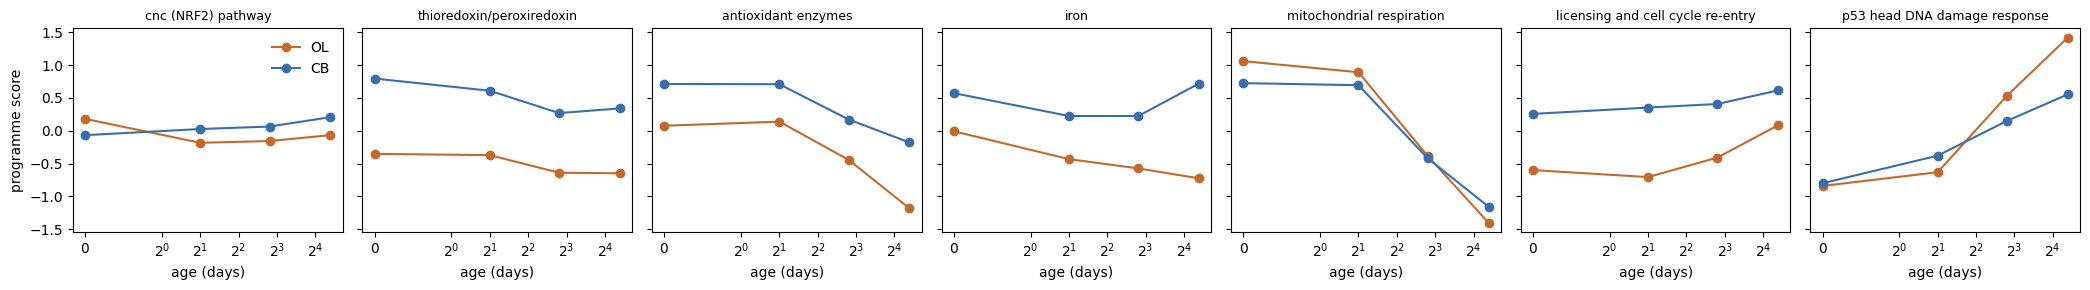

Saved to /content/drive/MyDrive/Colab Notebooks/route_b_fly_bulk


In [ ]:
#@title Cell 8 - Charts and saving
show = [n for n in scores.columns if not n.startswith("CONTROL")][:7]
fig, axes = plt.subplots(1, len(show), figsize=(3 * len(show), 3), sharey=True)
for ax, n in zip(np.atleast_1d(axes), show):
    for reg, col in (("OL", "#c26a2e"), ("CB", "#3b6ea8")):
        m = (d.region == reg).to_numpy()
        means = pd.Series(scores[n].to_numpy()[m]).groupby(d.age_days[m].to_numpy()).mean()
        ax.plot(means.index, means.values, "o-", color=col, label=reg)
    ax.set_xscale("symlog", base=2, linthresh=1); ax.set_title(n.split(": ")[1], fontsize=9); ax.set_xlabel("age (days)")
np.atleast_1d(axes)[0].set_ylabel("programme score"); np.atleast_1d(axes)[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(os.path.join(DATA_DIR, "chart_programmes_by_age.png"), dpi=150); plt.show()
for name, frame in {"bulk_programmes.csv": result, "bulk_genes.csv": gene_result, "bulk_scores.csv": scores.assign(**d[["region", "age_days", "sex"]])}.items():
    frame.to_csv(os.path.join(DATA_DIR, name), index=False)
print("Saved to", DATA_DIR)